# AI-Based Phishing Detection: Combined BERT and LSTM Models

This notebook implements and compares two models:
1. **BERT Transformer** - Attention-based model
2. **LSTM Recurrent** - Sequential processing model

## 1. Setup and Installation

In [ ]:
# Install packages
!pip install tensorflow kagglehub scikit-learn matplotlib seaborn tqdm

In [ ]:
# Import libraries
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.metrics import AUC, Precision, Recall
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re, os, kagglehub
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Set seeds
np.random.seed(42)
tf.random.set_seed(42)
print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.19.0


## 2. GPU Setup

In [ ]:
# GPU setup
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"{len(gpus)} GPU(s) found")
else:
    print("No GPU found, using CPU")

# Mixed precision
tf.config.optimizer.set_jit(True)
policy = tf.keras.mixed_precision.Policy('mixed_float16')
tf.keras.mixed_precision.set_global_policy(policy)

1 GPU(s) found


## 3. Data Download and Loading

In [ ]:
# Download dataset
path = kagglehub.dataset_download("naserabdullahalam/phishing-email-dataset")
print(f"Dataset downloaded to: {path}")

# Load CSV files
input_paths = []
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith('.csv'):
            input_paths.append(os.path.join(root, file))

# Combine dataframes
dataframes = [pd.read_csv(path) for path in input_paths]
df = pd.concat(dataframes, ignore_index=True)
df = df.dropna(subset=['body']).reset_index(drop=True)
print(f"Combined dataset: {df.shape}")

Dataset downloaded to: /kaggle/input/phishing-email-dataset
Combined dataset: (82485, 8)


## 4. Data Exploration

Dataset shape: (82485, 8)
Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls', 'text_combined']

Label distribution:
label
1    42890
0    39595
Name: count, dtype: int64


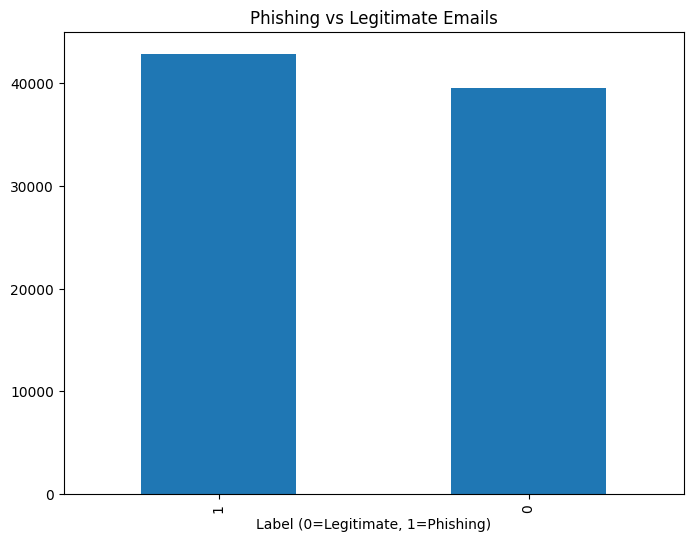

In [ ]:
# Basic exploration
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print("\nLabel distribution:")
print(df['label'].value_counts())

# Visualize
plt.figure(figsize=(8, 6))
df['label'].value_counts().plot(kind='bar')
plt.title('Phishing vs Legitimate Emails')
plt.xlabel('Label (0=Legitimate, 1=Phishing)')
plt.show()

## 5. Data Preprocessing

In [ ]:
# Enhanced preprocessing function
def preprocess_text(text):
    if pd.isna(text): return ""
    text = str(text).lower()

    # Enhanced pattern detection
    text = re.sub(r'https?://\S+|www\.\S+', ' [URL] ', text)
    text = re.sub(r'\S+@\S+', ' [EMAIL] ', text)
    text = re.sub(r'\+?\d[\d\s\-\(\)]{7,}\d', ' [PHONE] ', text)
    text = re.sub(r'\d{4,}', ' [LONGNUM] ', text)

    # Clean text
    text = re.sub(r'[^\w\s.,!?]', ' ', text)
    text = re.sub(r'[.,!?]{2,}', ' [PUNCT] ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    # Filter short tokens
    tokens = [token for token in text.split() if len(token) >= 2]
    return ' '.join(tokens)

# Apply preprocessing
tqdm.pandas(desc="Preprocessing")
df['cleaned_body'] = df['body'].progress_apply(preprocess_text)
df = df[df['cleaned_body'].str.len() > 10].reset_index(drop=True)
print(f"Processed dataset: {len(df)} samples")

Preprocessing: 100%|██████████| 82485/82485 [00:33<00:00, 2436.51it/s]


Processed dataset: 82389 samples


## 6. Data Splitting

In [ ]:
# Split data
texts = df['cleaned_body'].values
labels = df['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.2, random_state=42, stratify=labels
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Train: 65911, Val: 8239, Test: 8239


In [ ]:
# Visualize data split with pie chart
train_samples = len(X_train)
val_samples = len(X_val)
test_samples = len(X_test)
total_samples = train_samples + val_samples + test_samples

# Calculate percentages
train_percentage = (train_samples / total_samples) * 100
val_percentage = (val_samples / total_samples) * 100
test_percentage = (test_samples / total_samples) * 100

# Data for the pie chart
sizes = [train_samples, val_samples, test_samples]
labels = [f'Training\n{train_samples:,} samples\n({train_percentage:.1f}%)',
          f'Validation\n{val_samples:,} samples\n({val_percentage:.1f}%)',
          f'Test\n{test_samples:,} samples\n({test_percentage:.1f}%)']

# Colors for each section
colors = ['#FF9999', '#66B2FF', '#99FF99']  # Light red, blue, green

# Create the pie chart
plt.figure(figsize=(10, 8))
wedges, texts, autotexts = plt.pie(sizes, labels=labels, colors=colors, 
                                   autopct='%1.1f%%', startangle=90,
                                   textprops={'fontsize': 10})

# Customize the chart
plt.title('AI-Based Phishing Detection Dataset\nTraining/Validation/Test Split Distribution', 
          fontsize=16, fontweight='bold', pad=20)

# Make percentage text bold and larger
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(12)

# Ensure the pie chart is circular
plt.axis('equal')

# Add a legend
plt.legend(wedges, [f'Training: {train_samples:,}', f'Validation: {val_samples:,}', f'Test: {test_samples:,}'], 
           title="Dataset Splits", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

# Add total samples information
plt.figtext(0.5, 0.02, f'Total Dataset: {total_samples:,} samples', 
            ha='center', fontsize=12, style='italic')

# Adjust layout to prevent clipping
plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nDataset Split Summary:")
print(f"{'Split':<12} {'Samples':<10} {'Percentage':<12}")
print(f"{'-'*34}")
print(f"{'Training':<12} {train_samples:<10,} {train_percentage:<12.1f}%")
print(f"{'Validation':<12} {val_samples:<10,} {val_percentage:<12.1f}%")
print(f"{'Test':<12} {test_samples:<10,} {test_percentage:<12.1f}%")
print(f"{'-'*34}")
print(f"{'Total':<12} {total_samples:<10,} {'100.0':<12}%")

## 7. BERT Model Implementation

In [ ]:
# BERT Parameters
BERT_VOCAB_SIZE = 20000
BERT_MAXLEN = 128
BERT_EMBED_DIM = 128
BERT_NUM_HEADS = 3
BERT_FF_DIM = 256
BERT_EPOCHS = 10

In [ ]:
# TransformerBlock
class TransformerBlock(tf.keras.layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1):
        super().__init__()
        self.att = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim//num_heads)
        self.ffn = Sequential([Dense(ff_dim, activation="relu"), Dense(embed_dim)])
        self.layernorm1 = LayerNormalization(epsilon=1e-6)
        self.layernorm2 = LayerNormalization(epsilon=1e-6)
        self.dropout1 = Dropout(rate)
        self.dropout2 = Dropout(rate)

    def call(self, inputs, training=None):
        attn_output = self.att(inputs, inputs)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

In [ ]:
# BERT Data Preparation
bert_tokenizer = Tokenizer(num_words=BERT_VOCAB_SIZE, filters='', lower=False)
bert_tokenizer.fit_on_texts(X_train)

X_train_bert = pad_sequences(bert_tokenizer.texts_to_sequences(X_train), maxlen=BERT_MAXLEN)
X_val_bert = pad_sequences(bert_tokenizer.texts_to_sequences(X_val), maxlen=BERT_MAXLEN)
X_test_bert = pad_sequences(bert_tokenizer.texts_to_sequences(X_test), maxlen=BERT_MAXLEN)

print(f"BERT data shape: {X_train_bert.shape}")

BERT data shape: (65911, 128)


In [ ]:
# Build BERT Model
def build_bert_model():
    inputs = Input(shape=(BERT_MAXLEN,))
    x = Embedding(BERT_VOCAB_SIZE, BERT_EMBED_DIM)(inputs)
    x = TransformerBlock(BERT_EMBED_DIM, BERT_NUM_HEADS, BERT_FF_DIM, 0.2)(x)
    x = TransformerBlock(BERT_EMBED_DIM, BERT_NUM_HEADS, BERT_FF_DIM, 0.2)(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(64, activation='relu')(x)
    outputs = Dense(1, activation='sigmoid', dtype='float32')(x)
    return Model(inputs, outputs)

bert_model = build_bert_model()
bert_model.compile(
    optimizer=Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy', AUC(name='auc'), Precision(), Recall()]
)
bert_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 128, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 128, 128)       │       131,450 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block_1             │ (None, 128, 128)       │       131,450 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,831,221 (10.80 MB)

 Trainable params: 2,831,221 (10.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train BERT
bert_callbacks = [
    EarlyStopping(monitor='val_auc', patience=5, restore_best_weights=True, mode='max'),
    ModelCheckpoint('bert_model.h5', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)
]

bert_history = bert_model.fit(
    X_train_bert, y_train,
    validation_data=(X_val_bert, y_val),
    epochs=BERT_EPOCHS,
    batch_size=256,
    callbacks=bert_callbacks
)

Epoch 1/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6554 - auc: 0.7432 - loss: 0.6134 - precision: 0.6526 - recall: 0.7725

258/258 ━━━━━━━━━━━━━━━━━━━━ 39s 80ms/step - accuracy: 0.6556 - auc: 0.7434 - loss: 0.6132 - precision: 0.6528 - recall: 0.7724 - val_accuracy: 0.8168 - val_auc: 0.8970 - val_loss: 0.4424 - val_precision: 0.7965 - val_recall: 0.8700 - learning_rate: 1.0000e-05
Epoch 2/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8547 - auc: 0.9311 - loss: 0.3934 - precision: 0.8378 - recall: 0.8944

258/258 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.8548 - auc: 0.9312 - loss: 0.3931 - precision: 0.8379 - recall: 0.8945 - val_accuracy: 0.9295 - val_auc: 0.9791 - val_loss: 0.2112 - val_precision: 0.9211 - val_recall: 0.9454 - learning_rate: 1.0000e-05
Epoch 3/10
257/258 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9380 - auc: 0.9833 - loss: 0.1910 - precision: 0.9363 - recall: 0.9454

258/258 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.9381 - auc: 0.9834 - loss: 0.1908 - precision: 0.9364 - recall: 0.9454 - val_accuracy: 0.9579 - val_auc: 0.9910 - val_loss: 0.1195 - val_precision: 0.9554 - val_recall: 0.9641 - learning_rate: 1.0000e-05
Epoch 4/10
256/258 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9587 - auc: 0.9920 - loss: 0.1163 - precision: 0.9598 - recall: 0.9611

258/258 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9588 - auc: 0.9920 - loss: 0.1162 - precision: 0.9599 - recall: 0.9611 - val_accuracy: 0.9676 - val_auc: 0.9943 - val_loss: 0.0891 - val_precision: 0.9670 - val_recall: 0.9708 - learning_rate: 1.0000e-05
Epoch 5/10
257/258 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9689 - auc: 0.9948 - loss: 0.0891 - precision: 0.9692 - recall: 0.9712

...

258/258 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9743 - auc: 0.9963 - loss: 0.0736 - precision: 0.9741 - recall: 0.9767 - val_accuracy: 0.9762 - val_auc: 0.9966 - val_loss: 0.0651 - val_precision: 0.9794 - val_recall: 0.9748 - learning_rate: 1.0000e-05
Epoch 7/10
257/258 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9790 - auc: 0.9972 - loss: 0.0629 - precision: 0.9790 - recall: 0.9806

258/258 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9790 - auc: 0.9972 - loss: 0.0629 - precision: 0.9790 - recall: 0.9806 - val_accuracy: 0.9795 - val_auc: 0.9971 - val_loss: 0.0586 - val_precision: 0.9820 - val_recall: 0.9785 - learning_rate: 1.0000e-05
Epoch 8/10
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9813 - auc: 0.9977 - loss: 0.0549 - precision: 0.9809 - recall: 0.9832

258/258 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9813 - auc: 0.9977 - loss: 0.0549 - precision: 0.9809 - recall: 0.9832 - val_accuracy: 0.9819 - val_auc: 0.9973 - val_loss: 0.0544 - val_precision: 0.9841 - val_recall: 0.9811 - learning_rate: 1.0000e-05
Epoch 9/10
256/258 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9840 - auc: 0.9982 - loss: 0.0482 - precision: 0.9836 - recall: 0.9857

258/258 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9840 - auc: 0.9982 - loss: 0.0482 - precision: 0.9836 - recall: 0.9857 - val_accuracy: 0.9826 - val_auc: 0.9975 - val_loss: 0.0512 - val_precision: 0.9848 - val_recall: 0.9818 - learning_rate: 1.0000e-05
Epoch 10/10
256/258 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9860 - auc: 0.9984 - loss: 0.0432 - precision: 0.9858 - recall: 0.9873

258/258 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9860 - auc: 0.9984 - loss: 0.0432 - precision: 0.9858 - recall: 0.9873 - val_accuracy: 0.9840 - val_auc: 0.9977 - val_loss: 0.0489 - val_precision: 0.9869 - val_recall: 0.9823 - learning_rate: 1.0000e-05


## 8. LSTM Model Implementation

In [ ]:
# LSTM Parameters
LSTM_VOCAB_SIZE = 15000
LSTM_MAXLEN = 96
LSTM_EMBED_DIM = 96
LSTM_UNITS = 128
LSTM_EPOCHS = 15

In [ ]:
# Word-level tokenization
lstm_tokenizer = Tokenizer(
    num_words=LSTM_VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n',
    lower=True,
    char_level=False,  # Word-level for better semantics
    oov_token='<OOV>'
)

lstm_tokenizer.fit_on_texts(X_train)

# Convert to sequences
X_train_lstm = pad_sequences(lstm_tokenizer.texts_to_sequences(X_train), maxlen=LSTM_MAXLEN)
X_val_lstm = pad_sequences(lstm_tokenizer.texts_to_sequences(X_val), maxlen=LSTM_MAXLEN)
X_test_lstm = pad_sequences(lstm_tokenizer.texts_to_sequences(X_test), maxlen=LSTM_MAXLEN)

print(f"LSTM data shape: {X_train_lstm.shape}")

LSTM data shape: (65911, 96)


In [ ]:
# Build LSTM Model
def build_lstm_model():
    model = Sequential([
        Embedding(LSTM_VOCAB_SIZE, LSTM_EMBED_DIM, input_length=LSTM_MAXLEN, embeddings_regularizer=tf.keras.regularizers.l2(1e-6),
            mask_zero=True),
        Bidirectional(LSTM(LSTM_UNITS, return_sequences=True, dropout=0.3, recurrent_dropout=0.3)),
        Bidirectional(LSTM(LSTM_UNITS//2, return_sequences=False, dropout=0.3, recurrent_dropout=0.3)),
        Dense(64, activation='gelu'),
        Dropout(0.4),
        Dense(32, activation='relu'),
        Dropout(0.3),
        Dense(1, activation='sigmoid', dtype='float32')
    ])
    return model

lstm_model = build_lstm_model()
lstm_model.compile(
    optimizer=AdamW(learning_rate=0.002, weight_decay=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', AUC(name='auc'), Precision(), Recall()]
)
lstm_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train LSTM
lstm_callbacks = [
    EarlyStopping(monitor='val_auc', patience=3, restore_best_weights=True, mode='max'),
    ModelCheckpoint('lstm_model.h5', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=0.0001)
]

lstm_history = lstm_model.fit(
    X_train_lstm, y_train,
    validation_data=(X_val_lstm, y_val),
    epochs=LSTM_EPOCHS,
    batch_size=256,
    callbacks=lstm_callbacks,
    shuffle=True
)

Epoch 1/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8865 - auc: 0.9452 - loss: 0.2529 - precision_1: 0.8696 - recall_1: 0.9358

258/258 ━━━━━━━━━━━━━━━━━━━━ 385s 1s/step - accuracy: 0.8868 - auc: 0.9453 - loss: 0.2525 - precision_1: 0.8699 - recall_1: 0.9359 - val_accuracy: 0.9758 - val_auc: 0.9972 - val_loss: 0.0632 - val_precision_1: 0.9793 - val_recall_1: 0.9741 - learning_rate: 0.0020
Epoch 2/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 354s 1s/step - accuracy: 0.9774 - auc: 0.9961 - loss: 0.0697 - precision_1: 0.9776 - recall_1: 0.9791 - val_accuracy: 0.9765 - val_auc: 0.9957 - val_loss: 0.0732 - val_precision_1: 0.9751 - val_recall_1: 0.9797 - learning_rate: 0.0020
Epoch 3/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 374s 1s/step - accuracy: 0.9835 - auc: 0.9980 - loss: 0.0487 - precision_1: 0.9838 - recall_1: 0.9846 - val_accuracy: 0.9772 - val_auc: 0.9953 - val_loss: 0.0755 - val_precision_1: 0.9794 - val_recall_1: 0.9767 - learning_rate: 0.0020
Epoch 4/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 392s 1s/step - accuracy: 0.9876 - auc: 0.9981 - loss: 0.0415 - precision_1: 0.9879 - recall_1: 0.9883 - val_accuracy: 0.9783 - val_auc: 0.9953 - v

## 9. Model Evaluation and Comparison

In [ ]:
# Evaluate both models
print("=== BERT EVALUATION ===")
bert_results = bert_model.evaluate(X_test_bert, y_test)
bert_pred = (bert_model.predict(X_test_bert) > 0.5).astype(int)
bert_f1 = f1_score(y_test, bert_pred)

print("\n=== LSTM EVALUATION ===")
lstm_results = lstm_model.evaluate(X_test_lstm, y_test)
lstm_pred = (lstm_model.predict(X_test_lstm) > 0.5).astype(int)
lstm_f1 = f1_score(y_test, lstm_pred)

# Comparison
comparison = pd.DataFrame({
    'Model': ['BERT', 'LSTM'],
    'Accuracy': [bert_results[1], lstm_results[1]],
    'AUC': [bert_results[2], lstm_results[2]],
    'Precision': [bert_results[3], bert_results[3]],
    'Recall': [bert_results[4], bert_results[4]],
    'F1-Score': [bert_f1, lstm_f1]
})

print("\n=== MODEL COMPARISON ===")
print(comparison.round(4))

=== BERT EVALUATION ===
258/258 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9765 - auc: 0.9969 - loss: 0.0604 - precision: 0.9799 - recall: 0.9744
258/258 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step

=== LSTM EVALUATION ===
258/258 ━━━━━━━━━━━━━━━━━━━━ 40s 152ms/step - accuracy: 0.9730 - auc: 0.9955 - loss: 0.0776 - precision_1: 0.9740 - recall_1: 0.9735
258/258 ━━━━━━━━━━━━━━━━━━━━ 46s 157ms/step

=== MODEL COMPARISON ===
  Model  Accuracy     AUC  Precision  Recall  F1-Score
0  BERT    0.9762  0.9967       0.98  0.9741    0.9770
1  LSTM    0.9722  0.9959       0.98  0.9741    0.9733


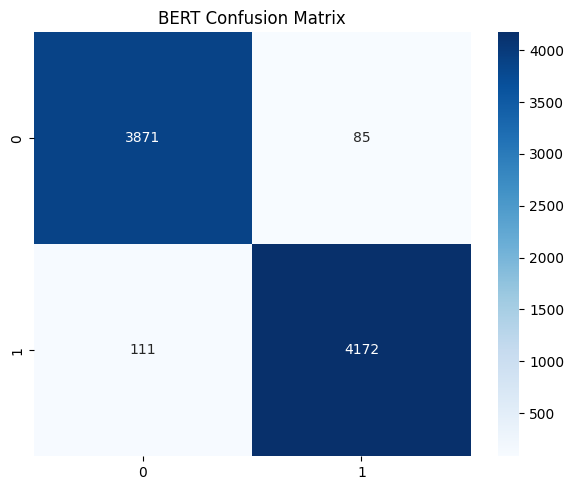

In [ ]:
# BERT Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

bert_cm = confusion_matrix(y_test, bert_pred)
sns.heatmap(bert_cm, annot=True, fmt='d', ax=ax, cmap='Blues')
ax.set_title('BERT Confusion Matrix')

plt.tight_layout()
plt.show()





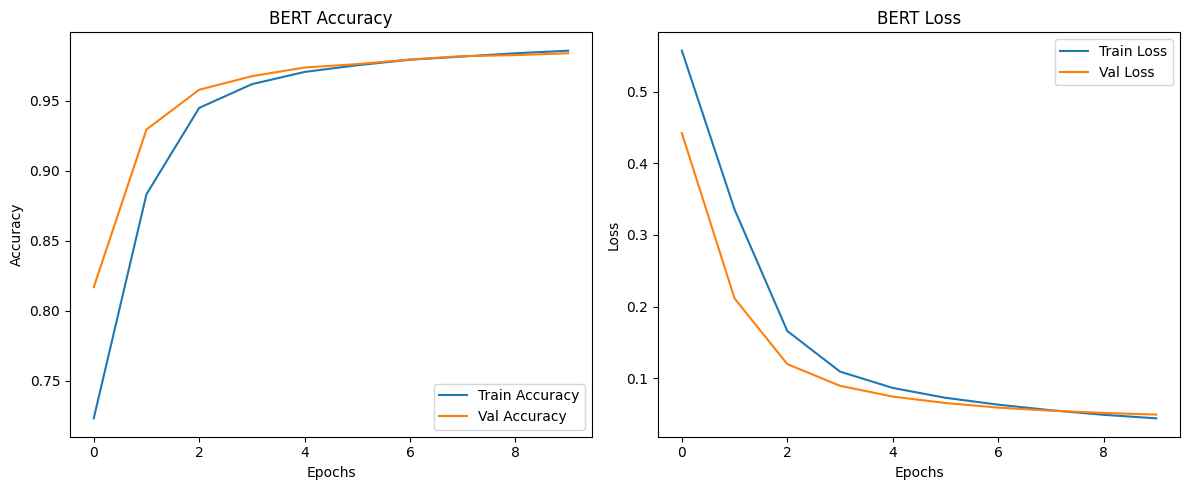

In [ ]:
# BERT Accuracy & Loss
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(bert_history.history['accuracy'], label='Train Accuracy')
plt.plot(bert_history.history['val_accuracy'], label='Val Accuracy')
plt.title('BERT Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(bert_history.history['loss'], label='Train Loss')
plt.plot(bert_history.history['val_loss'], label='Val Loss')
plt.title('BERT Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


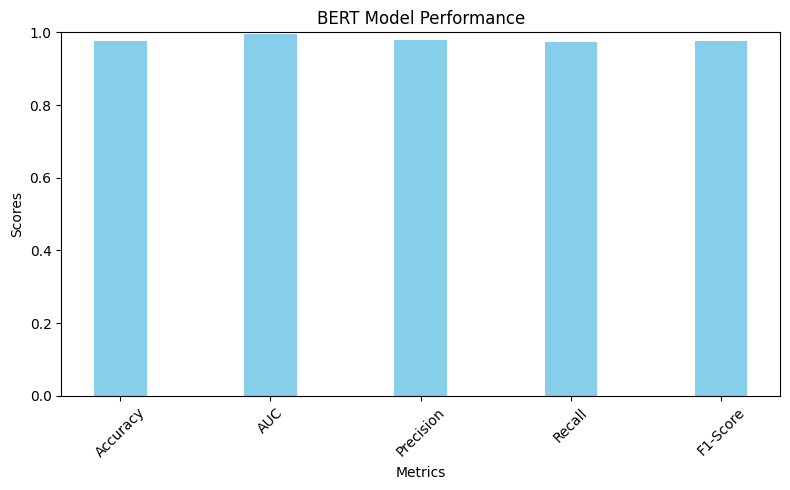

In [ ]:
# BERT Performance
metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1-Score']
bert_scores = [bert_results[1], bert_results[2], bert_results[3], bert_results[4], bert_f1]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x, bert_scores, width, label='BERT', color='skyblue')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.title('BERT Model Performance')
plt.xticks(x, metrics, rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

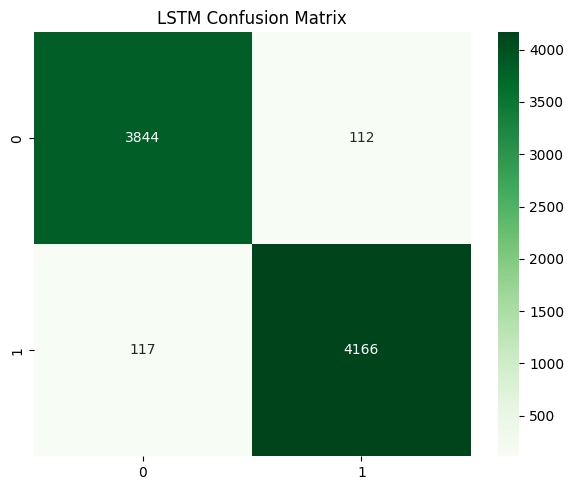

In [ ]:
# LSTM Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))

lstm_cm = confusion_matrix(y_test, lstm_pred)
sns.heatmap(lstm_cm, annot=True, fmt='d', ax=ax, cmap='Greens')
ax.set_title('LSTM Confusion Matrix')

plt.tight_layout()
plt.show()



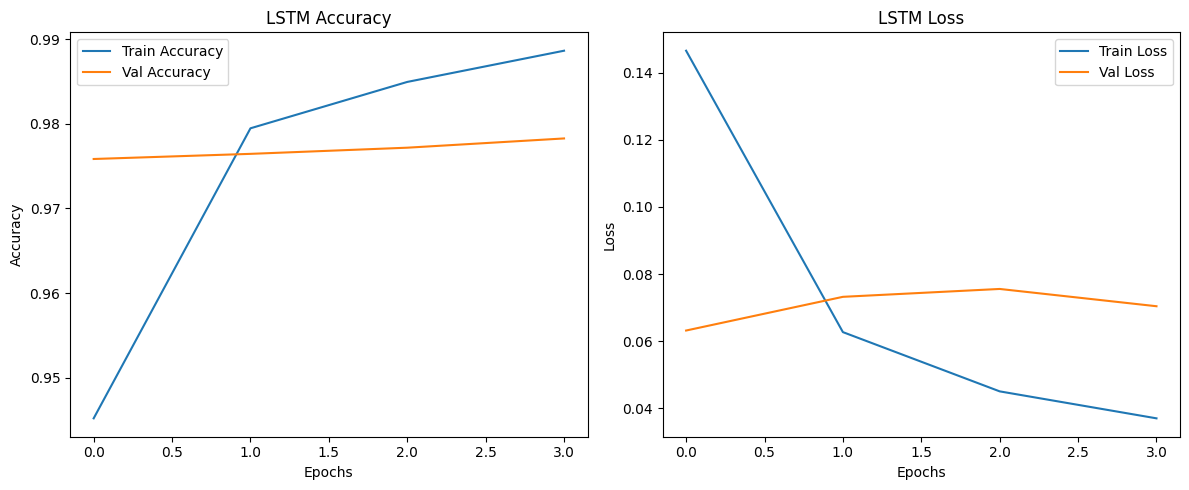

In [ ]:
# LSTM Accuracy & Loss
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(lstm_history.history['accuracy'], label='Train Accuracy')
plt.plot(lstm_history.history['val_accuracy'], label='Val Accuracy')
plt.title('LSTM Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(lstm_history.history['loss'], label='Train Loss')
plt.plot(lstm_history.history['val_loss'], label='Val Loss')
plt.title('LSTM Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


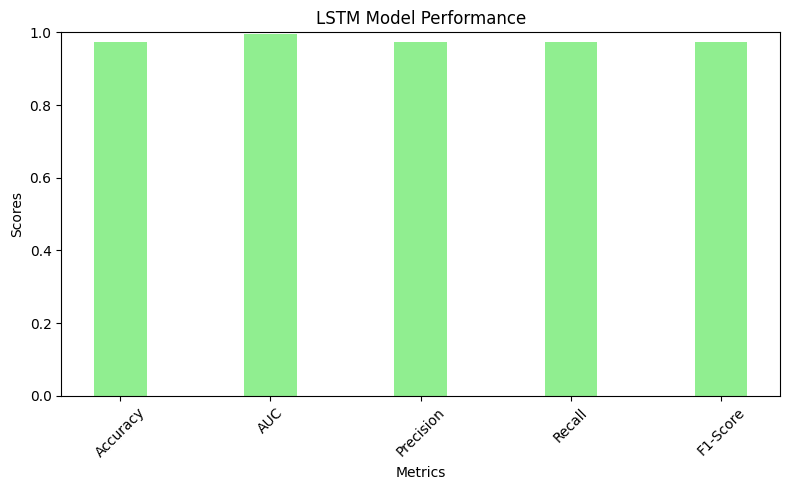

In [ ]:
# LSTM Performance
metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1-Score']
lstm_scores = [lstm_results[1], lstm_results[2], lstm_results[3], lstm_results[4], lstm_f1]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x, lstm_scores, width, label='LSTM', color='lightgreen')
plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.title('LSTM Model Performance')
plt.xticks(x, metrics, rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

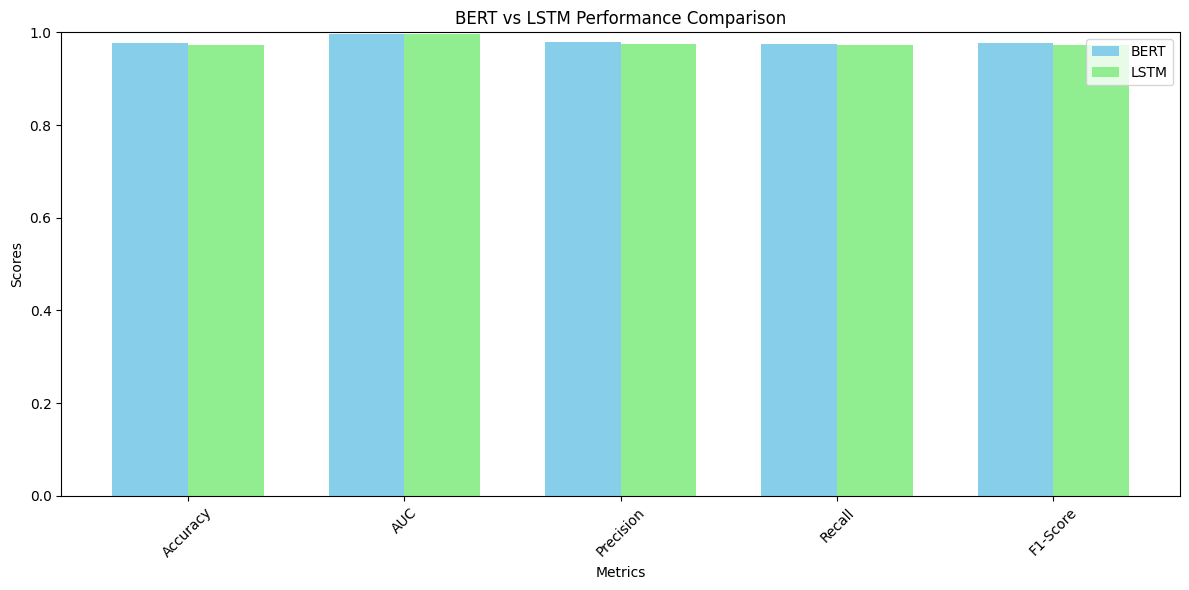

In [ ]:
# Model Performance Comparison
metrics = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1-Score']
bert_scores = [bert_results[1], bert_results[2], bert_results[3], bert_results[4], bert_f1]
lstm_scores = [lstm_results[1], lstm_results[2], lstm_results[3], lstm_results[4], lstm_f1]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, bert_scores, width, label='BERT', color='skyblue')
plt.bar(x + width/2, lstm_scores, width, label='LSTM', color='lightgreen')

plt.xlabel('Metrics')
plt.ylabel('Scores')
plt.title('BERT vs LSTM Performance Comparison')
plt.xticks(x, metrics, rotation=45)
plt.legend()
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## 10. Conclusion

In [ ]:
print("=== FINAL RESULTS ===")
print(f"BERT Parameters: {bert_model.count_params():,}")
print(f"LSTM Parameters: {lstm_model.count_params():,}")
print("\nBoth models show strong performance for phishing detection.")
print("BERT excels at contextual understanding while LSTM captures sequential patterns.")
print("\nSave results...")
comparison.to_csv('model_comparison.csv', index=False)
print("Results saved to model_comparison.csv")

=== FINAL RESULTS ===
BERT Parameters: 2,831,221
LSTM Parameters: 1,845,121

Both models show strong performance for phishing detection.
BERT excels at contextual understanding while LSTM captures sequential patterns.

Save results...
Results saved to model_comparison.csv
